Step 1 — Set up the environment

In [1]:
!pip install nltk pandas

In [2]:
import pandas as pd
import nltk
import re

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /Users/wangying/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/wangying/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

Step 2 — Load the customer reviews dataset
For this exercise, you may use a small sample dataset or replace it with a real customer review dataset.

Create a sample DataFrame:

In [4]:
reviews = [
    "This product is AMAZING! I absolutely love it.",
    "The service was terrible, and the staff were very rude.",
    "I purchased this product last week. It works perfectly!",
    "The product is not good. I would not recommend it.",
    "Great quality, excellent customer service, and fast delivery!",
    "The food was delicious, but the restaurant was too expensive.",
    "I am disappointed with the quality of this product.",
    "The employees were helpful and friendly. I will come back!"
]

df = pd.DataFrame({
    'review': reviews
})

print(df.head())

                                              review
0     This product is AMAZING! I absolutely love it.
1  The service was terrible, and the staff were v...
2  I purchased this product last week. It works p...
3  The product is not good. I would not recommend...
4  Great quality, excellent customer service, and...


Step 3 — Lowercasing
Convert all text to lowercase to standardize the text and prevent words such as Product, PRODUCT, and product from being treated as different tokens.

Implement a function:

In [5]:
def lowercase_text(text):
    return text.lower()

In [6]:
df['lowercase'] = df['review'].apply(lowercase_text)

print(df[['review', 'lowercase']])

                                              review  \
0     This product is AMAZING! I absolutely love it.   
1  The service was terrible, and the staff were v...   
2  I purchased this product last week. It works p...   
3  The product is not good. I would not recommend...   
4  Great quality, excellent customer service, and...   
5  The food was delicious, but the restaurant was...   
6  I am disappointed with the quality of this pro...   
7  The employees were helpful and friendly. I wil...   

                                           lowercase  
0     this product is amazing! i absolutely love it.  
1  the service was terrible, and the staff were v...  
2  i purchased this product last week. it works p...  
3  the product is not good. i would not recommend...  
4  great quality, excellent customer service, and...  
5  the food was delicious, but the restaurant was...  
6  i am disappointed with the quality of this pro...  
7  the employees were helpful and friendly. i wil...  


Step 4 — Tokenization
Tokenization splits a sentence into individual words or tokens.

For example:

"I love this product!"

Becomes:

["i", "love", "this", "product", "!"]

Implement tokenization using NLTK:

In [7]:
def tokenize_text(text):
    return word_tokenize(text)

In [8]:
df['tokens'] = df['lowercase'].apply(tokenize_text)

print(df[['lowercase', 'tokens']])

                                           lowercase  \
0     this product is amazing! i absolutely love it.   
1  the service was terrible, and the staff were v...   
2  i purchased this product last week. it works p...   
3  the product is not good. i would not recommend...   
4  great quality, excellent customer service, and...   
5  the food was delicious, but the restaurant was...   
6  i am disappointed with the quality of this pro...   
7  the employees were helpful and friendly. i wil...   

                                              tokens  
0  [this, product, is, amazing, !, i, absolutely,...  
1  [the, service, was, terrible, ,, and, the, sta...  
2  [i, purchased, this, product, last, week, ., i...  
3  [the, product, is, not, good, ., i, would, not...  
4  [great, quality, ,, excellent, customer, servi...  
5  [the, food, was, delicious, ,, but, the, resta...  
6  [i, am, disappointed, with, the, quality, of, ...  
7  [the, employees, were, helpful, and, friendly,...  


Step 5 — Punctuation handling
Punctuation may not be useful for some NLP tasks, so you will implement a function to remove punctuation.

Use regular expressions:

In [9]:
def remove_punctuation(text):
    text = re.sub(r'[^\w\s]', '', text)
    return text

In [10]:
df['no_punctuation'] = df['lowercase'].apply(remove_punctuation)

print(df[['lowercase', 'no_punctuation']])

                                           lowercase  \
0     this product is amazing! i absolutely love it.   
1  the service was terrible, and the staff were v...   
2  i purchased this product last week. it works p...   
3  the product is not good. i would not recommend...   
4  great quality, excellent customer service, and...   
5  the food was delicious, but the restaurant was...   
6  i am disappointed with the quality of this pro...   
7  the employees were helpful and friendly. i wil...   

                                      no_punctuation  
0       this product is amazing i absolutely love it  
1  the service was terrible and the staff were ve...  
2  i purchased this product last week it works pe...  
3   the product is not good i would not recommend it  
4  great quality excellent customer service and f...  
5  the food was delicious but the restaurant was ...  
6  i am disappointed with the quality of this pro...  
7  the employees were helpful and friendly i will...  


In [11]:
def clean_tokens(tokens):
    return [
        token for token in tokens
        if token.isalnum()
    ]

In [12]:
df['clean_tokens'] = df['tokens'].apply(clean_tokens)

print(df[['tokens', 'clean_tokens']])

                                              tokens  \
0  [this, product, is, amazing, !, i, absolutely,...   
1  [the, service, was, terrible, ,, and, the, sta...   
2  [i, purchased, this, product, last, week, ., i...   
3  [the, product, is, not, good, ., i, would, not...   
4  [great, quality, ,, excellent, customer, servi...   
5  [the, food, was, delicious, ,, but, the, resta...   
6  [i, am, disappointed, with, the, quality, of, ...   
7  [the, employees, were, helpful, and, friendly,...   

                                        clean_tokens  
0  [this, product, is, amazing, i, absolutely, lo...  
1  [the, service, was, terrible, and, the, staff,...  
2  [i, purchased, this, product, last, week, it, ...  
3  [the, product, is, not, good, i, would, not, r...  
4  [great, quality, excellent, customer, service,...  
5  [the, food, was, delicious, but, the, restaura...  
6  [i, am, disappointed, with, the, quality, of, ...  
7  [the, employees, were, helpful, and, friendly,...  


Step 6 — Stop-word removal
Stop words are common words that may contribute relatively little to the meaning of a text in certain NLP tasks.

Examples include:
- the
- is
- a
- an
- and
- of
- to
- in
- it
Use NLTK's English stop-word list:

In [13]:
stop_words = set(stopwords.words('english'))

In [14]:
def remove_stopwords(tokens):
    return [
        token for token in tokens
        if token not in stop_words
    ]

In [15]:
df['filtered_tokens'] = df['clean_tokens'].apply(remove_stopwords)

print(df[['clean_tokens', 'filtered_tokens']])

                                        clean_tokens  \
0  [this, product, is, amazing, i, absolutely, lo...   
1  [the, service, was, terrible, and, the, staff,...   
2  [i, purchased, this, product, last, week, it, ...   
3  [the, product, is, not, good, i, would, not, r...   
4  [great, quality, excellent, customer, service,...   
5  [the, food, was, delicious, but, the, restaura...   
6  [i, am, disappointed, with, the, quality, of, ...   
7  [the, employees, were, helpful, and, friendly,...   

                                     filtered_tokens  
0               [product, amazing, absolutely, love]  
1                   [service, terrible, staff, rude]  
2  [purchased, product, last, week, works, perfec...  
3                  [product, good, would, recommend]  
4  [great, quality, excellent, customer, service,...  
5           [food, delicious, restaurant, expensive]  
6                   [disappointed, quality, product]  
7         [employees, helpful, friendly, come, back]  


In [16]:
stop_words = set(stopwords.words('english'))

negation_words = {'not', 'no', 'nor', 'never'}

stop_words = stop_words - negation_words

Step 7 — Stemming
Stemming reduces words to their root-like forms by removing prefixes or suffixes. The resulting word may not be a valid dictionary word.

Examples:
Original	Stem
playing	play
played	play
studies	studi
caring	care
delicious	delicious

Use NLTK's Porter Stemmer:

In [17]:
stemmer = PorterStemmer()

In [18]:
def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

In [19]:
df['stemmed_tokens'] = df['filtered_tokens'].apply(stem_tokens)

print(df[['filtered_tokens', 'stemmed_tokens']])

                                     filtered_tokens  \
0               [product, amazing, absolutely, love]   
1                   [service, terrible, staff, rude]   
2  [purchased, product, last, week, works, perfec...   
3                  [product, good, would, recommend]   
4  [great, quality, excellent, customer, service,...   
5           [food, delicious, restaurant, expensive]   
6                   [disappointed, quality, product]   
7         [employees, helpful, friendly, come, back]   

                                      stemmed_tokens  
0                     [product, amaz, absolut, love]  
1                     [servic, terribl, staff, rude]  
2    [purchas, product, last, week, work, perfectli]  
3                  [product, good, would, recommend]  
4  [great, qualiti, excel, custom, servic, fast, ...  
5                    [food, delici, restaur, expens]  
6                     [disappoint, qualiti, product]  
7              [employe, help, friendli, come, back]  


Step 8 — Lemmatization
Lemmatization converts words into their dictionary base forms, known as lemmas.

Unlike stemming, lemmatization attempts to produce meaningful English words.

Step 8 — Lemmatization
Lemmatization converts words into their dictionary base forms, known as lemmas.

Unlike stemming, lemmatization attempts to produce meaningful English words.

In [20]:
lemmatizer = WordNetLemmatizer()

In [21]:
def lemmatize_tokens(tokens):
    return [
        lemmatizer.lemmatize(token)
        for token in tokens
    ]

In [22]:
df['lemmatized_tokens'] = df['filtered_tokens'].apply(lemmatize_tokens)

print(df[['filtered_tokens', 'lemmatized_tokens']])

                                     filtered_tokens  \
0               [product, amazing, absolutely, love]   
1                   [service, terrible, staff, rude]   
2  [purchased, product, last, week, works, perfec...   
3                  [product, good, would, recommend]   
4  [great, quality, excellent, customer, service,...   
5           [food, delicious, restaurant, expensive]   
6                   [disappointed, quality, product]   
7         [employees, helpful, friendly, come, back]   

                                   lemmatized_tokens  
0               [product, amazing, absolutely, love]  
1                   [service, terrible, staff, rude]  
2  [purchased, product, last, week, work, perfectly]  
3                  [product, good, would, recommend]  
4  [great, quality, excellent, customer, service,...  
5           [food, delicious, restaurant, expensive]  
6                   [disappointed, quality, product]  
7          [employee, helpful, friendly, come, back]  


In [23]:
from nltk import pos_tag

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'  # adjective
    elif tag.startswith('V'):
        return 'v'  # verb
    elif tag.startswith('N'):
        return 'n'  # noun
    elif tag.startswith('R'):
        return 'r'  # adverb
    else:
        return 'n'

In [24]:
def lemmatize_tokens_pos(tokens):
    tagged_tokens = pos_tag(tokens)

    return [
        lemmatizer.lemmatize(
            word,
            get_wordnet_pos(tag)
        )
        for word, tag in tagged_tokens
    ]

In [25]:
df['pos_lemmatized'] = df['filtered_tokens'].apply(
    lemmatize_tokens_pos
)

print(df[['filtered_tokens', 'pos_lemmatized']])

                                     filtered_tokens  \
0               [product, amazing, absolutely, love]   
1                   [service, terrible, staff, rude]   
2  [purchased, product, last, week, works, perfec...   
3                  [product, good, would, recommend]   
4  [great, quality, excellent, customer, service,...   
5           [food, delicious, restaurant, expensive]   
6                   [disappointed, quality, product]   
7         [employees, helpful, friendly, come, back]   

                                      pos_lemmatized  
0                 [product, amaze, absolutely, love]  
1                   [service, terrible, staff, rude]  
2   [purchase, product, last, week, work, perfectly]  
3                  [product, good, would, recommend]  
4  [great, quality, excellent, customer, service,...  
5           [food, delicious, restaurant, expensive]  
6                   [disappointed, quality, product]  
7          [employee, helpful, friendly, come, back]  


In [26]:
def preprocess_text(text, method='lemmatization'):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Stop-word removal
    tokens = [
        token for token in tokens
        if token not in stop_words
    ]

    # 5. Stemming or lemmatization
    if method == 'stemming':
        tokens = stem_tokens(tokens)

    elif method == 'lemmatization':
        tokens = lemmatize_tokens(tokens)

    return tokens

In [27]:
df['preprocessed_stemmed'] = df['review'].apply(
    lambda text: preprocess_text(text, method='stemming')
)

df['preprocessed_lemmatized'] = df['review'].apply(
    lambda text: preprocess_text(text, method='lemmatization')
)

print(df[['review', 'preprocessed_stemmed', 'preprocessed_lemmatized']])

                                              review  \
0     This product is AMAZING! I absolutely love it.   
1  The service was terrible, and the staff were v...   
2  I purchased this product last week. It works p...   
3  The product is not good. I would not recommend...   
4  Great quality, excellent customer service, and...   
5  The food was delicious, but the restaurant was...   
6  I am disappointed with the quality of this pro...   
7  The employees were helpful and friendly. I wil...   

                                preprocessed_stemmed  \
0                     [product, amaz, absolut, love]   
1                     [servic, terribl, staff, rude]   
2    [purchas, product, last, week, work, perfectli]   
3        [product, not, good, would, not, recommend]   
4  [great, qualiti, excel, custom, servic, fast, ...   
5                    [food, delici, restaur, expens]   
6                     [disappoint, qualiti, product]   
7              [employe, help, friendli, come, 

In [28]:
df['processed_text'] = df['preprocessed_lemmatized'].apply(
    lambda tokens: ' '.join(tokens)
)

print(df[['review', 'processed_text']])

                                              review  \
0     This product is AMAZING! I absolutely love it.   
1  The service was terrible, and the staff were v...   
2  I purchased this product last week. It works p...   
3  The product is not good. I would not recommend...   
4  Great quality, excellent customer service, and...   
5  The food was delicious, but the restaurant was...   
6  I am disappointed with the quality of this pro...   
7  The employees were helpful and friendly. I wil...   

                                      processed_text  
0                    product amazing absolutely love  
1                        service terrible staff rude  
2         purchased product last week work perfectly  
3               product not good would not recommend  
4  great quality excellent customer service fast ...  
5                food delicious restaurant expensive  
6                       disappointed quality product  
7                employee helpful friendly come back  


Step 10 — Evaluate the preprocessing results
Create a comparison table showing the original reviews and the results of each preprocessing technique.

In [29]:
comparison = df[
    [
        'review',
        'lowercase',
        'clean_tokens',
        'filtered_tokens',
        'stemmed_tokens',
        'lemmatized_tokens'
    ]
]

display(comparison)

,review,lowercase,clean_tokens,filtered_tokens,stemmed_tokens,lemmatized_tokens
0,This product is AMAZING! I absolutely love it.,this product is amazing! i absolutely love it.,"[this, product, is, amazing, i, absolutely, lo...","[product, amazing, absolutely, love]","[product, amaz, absolut, love]","[product, amazing, absolutely, love]"
1,"The service was terrible, and the staff were v...","the service was terrible, and the staff were v...","[the, service, was, terrible, and, the, staff,...","[service, terrible, staff, rude]","[servic, terribl, staff, rude]","[service, terrible, staff, rude]"
2,I purchased this product last week. It works p...,i purchased this product last week. it works p...,"[i, purchased, this, product, last, week, it, ...","[purchased, product, last, week, works, perfec...","[purchas, product, last, week, work, perfectli]","[purchased, product, last, week, work, perfectly]"
3,The product is not good. I would not recommend...,the product is not good. i would not recommend...,"[the, product, is, not, good, i, would, not, r...","[product, good, would, recommend]","[product, good, would, recommend]","[product, good, would, recommend]"
4,"Great quality, excellent customer service, and...","great quality, excellent customer service, and...","[great, quality, excellent, customer, service,...","[great, quality, excellent, customer, service,...","[great, qualiti, excel, custom, servic, fast, ...","[great, quality, excellent, customer, service,..."
5,"The food was delicious, but the restaurant was...","the food was delicious, but the restaurant was...","[the, food, was, delicious, but, the, restaura...","[food, delicious, restaurant, expensive]","[food, delici, restaur, expens]","[food, delicious, restaurant, expensive]"
6,I am disappointed with the quality of this pro...,i am disappointed with the quality of this pro...,"[i, am, disappointed, with, the, quality, of, ...","[disappointed, quality, product]","[disappoint, qualiti, product]","[disappointed, quality, product]"
7,The employees were helpful and friendly. I wil...,the employees were helpful and friendly. i wil...,"[the, employees, were, helpful, and, friendly,...","[employees, helpful, friendly, come, back]","[employe, help, friendli, come, back]","[employee, helpful, friendly, come, back]"


In [30]:
df['original_word_count'] = df['review'].apply(
    lambda text: len(word_tokenize(text))
)

df['processed_word_count'] = df['preprocessed_lemmatized'].apply(
    len
)

print("Original total tokens:", df['original_word_count'].sum())

print("Processed total tokens:", df['processed_word_count'].sum())

print("Token reduction percentage:",
      round(
          (1 - df['processed_word_count'].sum() /
           df['original_word_count'].sum()) * 100,
          2
      ),
      "%"
)

Original total tokens: 90
Processed total tokens: 39
Token reduction percentage: 56.67 %


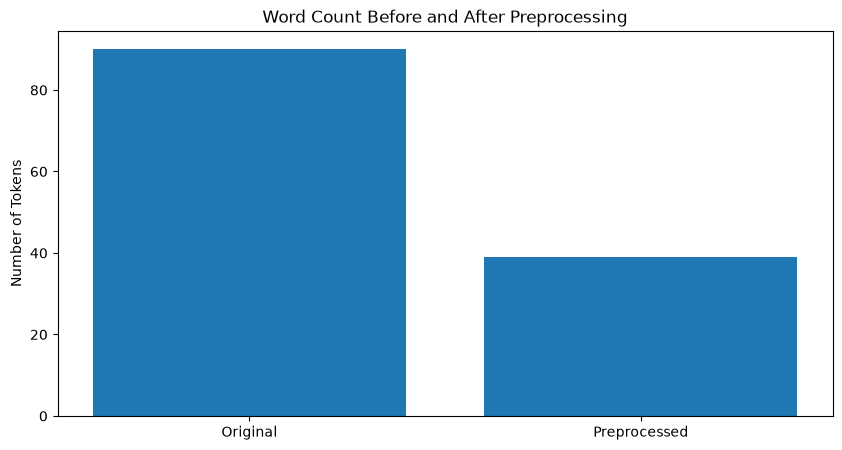

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    ['Original', 'Preprocessed'],
    [
        df['original_word_count'].sum(),
        df['processed_word_count'].sum()
    ]
)

plt.title('Word Count Before and After Preprocessing')
plt.ylabel('Number of Tokens')

plt.show()

In [32]:
def basic_preprocessing(text):
    text = text.lower()
    return word_tokenize(text)


def intermediate_preprocessing(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)

    tokens = word_tokenize(text)

    tokens = [
        token for token in tokens
        if token not in stop_words
    ]

    return tokens


df['method_a'] = df['review'].apply(basic_preprocessing)

df['method_b'] = df['review'].apply(intermediate_preprocessing)

df['method_c'] = df['review'].apply(
    lambda text: preprocess_text(text, method='lemmatization')
)

In [33]:
sentiment_reviews = [
    "This product is good.",
    "This product is not good.",
    "This product is very good.",
    "This product is never good."
]

for review in sentiment_reviews:
    print("Original:", review)
    print("Processed:", preprocess_text(review))
    print()

Original: This product is good.
Processed: ['product', 'good']

Original: This product is not good.
Processed: ['product', 'not', 'good']

Original: This product is very good.
Processed: ['product', 'good']

Original: This product is never good.
Processed: ['product', 'never', 'good']

